Event Study

# Setup

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Uncomment and run the following code to import the libraries.

In [1]:
import pandas as pd
import yfinance as yf

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm # for OLS

import numpy as np

# Introduction

### What is event study?


* An event study is a statistical method to assess the impact of an event on the value of a firm.  

* For example, the announcement of a merger between two business entities can be analyzed to see whether investors believe the merger will create or destroy value.

### Why is event study useful?

Common appications of event study:

* Security fraud litigation 
* Financial market regulation
* Corporate compliance
* ...

## Elon Musk's Tweet

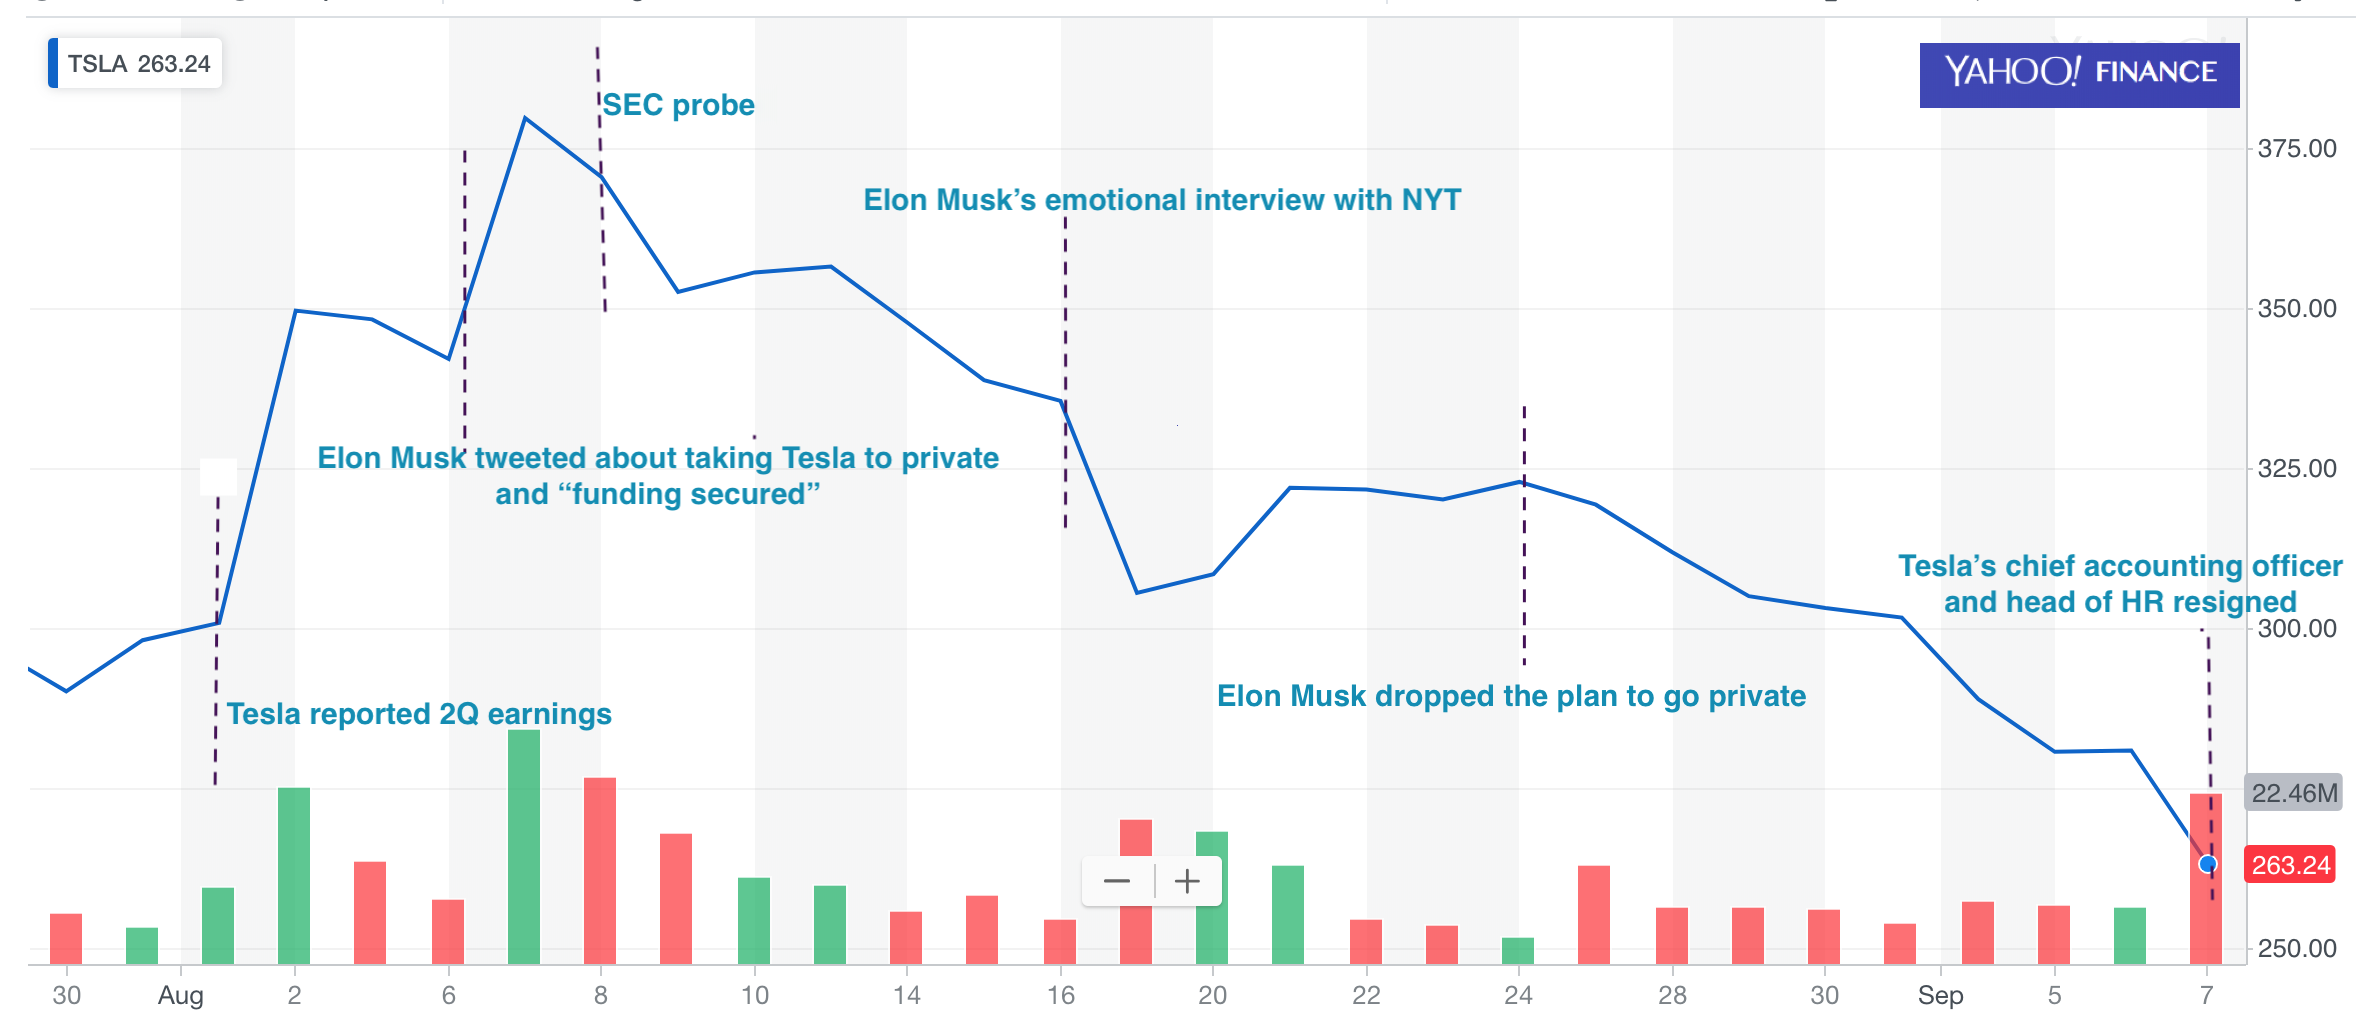

* **The Tweet:** On Aug 7, 2018 Elon Musk shocked the market by tweeting that he was considering taking Tesla private at $420 a share and had "funding secured."

* Q: Can an investor who purchased the Tesla stock at market close on Aug 7 sue Tesla or Elon Musk for the loss? 

* Q: How much is the loss?

# Data Preparation

## Stock Price Data

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Uncomment and run the following code to download TSLA stock data from Yahoo Finance.

In [2]:
stock_symbol = "TSLA"
df = yf.download(stock_symbol,
                  start="1900-1-1",
                  auto_adjust=True,
                  multi_level_index=False,
                  progress=False)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `df`.

In [3]:
df.head()

,Close,High,Low,Open,Volume
Date,,,,,
2010-06-29,1.592667,1.666667,1.169333,1.266667,281494500
2010-06-30,1.588667,2.028000,1.553333,1.719333,257806500
2010-07-01,1.464000,1.728000,1.351333,1.666667,123282000
2010-07-02,1.280000,1.540000,1.247333,1.533333,77097000
2010-07-06,1.074000,1.333333,1.055333,1.333333,103003500


## The Event

* "Am considering taking Tesla private at $420. Funding secured," Musk tweeted at 12:48 p.m. Tuesday, Aug 7, 2018.

<mark>Q: How to define the event date so the notebook can be reused for another event?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Convert the date of the tweet, `"2018-08-07"`, to a timestamp with `pd.to_datetime()` and store it in `event_date`.

In [4]:
event_date = pd.to_datetime("2018-08-07")

### Stock Prices around the Event Date

<mark>Q: How to plot a stock's price in a window of days around the event date?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Use `.loc` to select the `"Close"` column of `df` from 10 days before to 10 days after `event_date`, using `pd.DateOffset(days=10)`, and plot it with the title `f"Tesla Stock Price around {event_date}"`. Uncomment and run the following code.

<Axes: title={'center': 'Tesla Stock Price around 2018-08-07 00:00:00'}, xlabel='Date'>

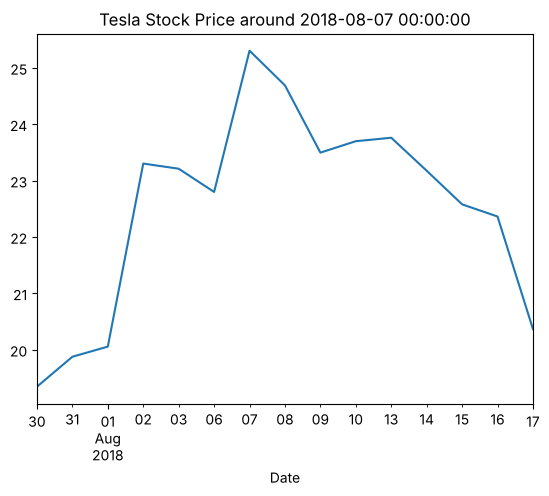

In [5]:
df.loc[event_date - pd.DateOffset(days=10)
      :event_date + pd.DateOffset(days=10), "Close"] \
      .plot(title=f"Tesla Stock Price around {event_date}")

## Daily Return

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate Tesla's daily return in percent by applying `.pct_change()` to the `"Close"` column of `df` and multiplying by `100`. Store it in `r_i`, and set its name to `"r_i"`.

In [6]:
r_i = df["Close"].pct_change() * 100
r_i.name = "r_i"

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_i`.

In [7]:
r_i.head()

Date
2010-06-29          NaN
2010-06-30    -0.251148
2010-07-01    -7.847274
2010-07-02   -12.568307
2010-07-06   -16.093748
Name: r_i, dtype: float64

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Use `.loc` to get the return on `event_date` from `r_i`, store it in `r_i_event_date`, and display it.

In [8]:
r_i_event_date = r_i.loc[event_date]
r_i_event_date

np.float64(10.988623587715551)

# Question and Methodology

## Daily Returns around the Event Date

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Slice `r_i` with square brackets from 10 days before to 10 days after `event_date`, using `pd.DateOffset(days=10)`, and plot it with the title `f"Daily Returns around {event_date}"`. Uncomment and run the following code.

<Axes: title={'center': 'Daily Returns around 2018-08-07 00:00:00'}, xlabel='Date'>

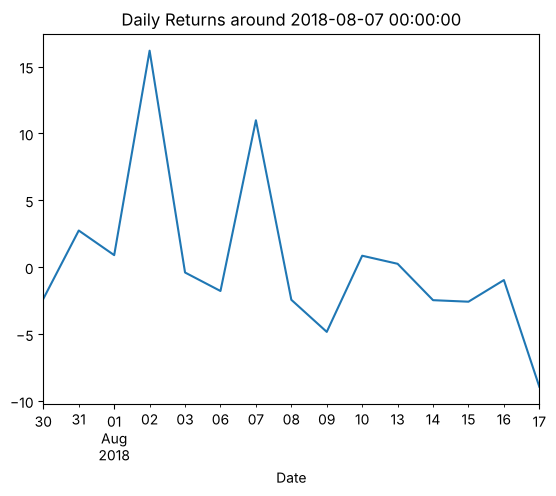

In [9]:
r_i[event_date - pd.DateOffset(days=10)
   :event_date + pd.DateOffset(days=10)].plot(title=f"Daily Returns around {event_date}")

### The Question

* On the date of tweet, the stock return was 11%.
* What contribute to the return? 
  1. The event 
  2. Overall market movement 
  3. Other news about the company 
* Need to control for the exposure to the overall market movment. 
  - A **market model** can be used: $$r_i = a + b \times r_M + \epsilon_i$$ 
  - We will use linear regression to estiamte a and b, and then apply the model on the event date to measure the **predicted return** $E[r_i] = a + b \times r_M$ 
  - Then **abnormal return** is calculated as $$r_i - E[r_i]$$

* References:
  * The paper "Econometrics of Event Studies" by S. P Khotari and Jerold B. Warner will give you a deeper understanding of the event study methodology: https://www.bu.edu/econ/files/2011/01/KothariWarner2.pdf
  * You may also be interested in "Event Studies in Economics and
Finance" by A. Craig MacKinlay: https://pdfs.semanticscholar.org/aac6/83a678a12a3dcd73389aac7289868847ea73.pdf

## Market Return

First we import S&P 500 Total Return Index from Yahoo Finance (ticker symbol ^SP500TR).

<mark>Q: How to get a market return that includes dividends?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Download the S&P 500 Total Return Index, ticker `"^SP500TR"`, into `SP500TR` with `yf.download()`. Uncomment and run the following code.

In [10]:
SP500TR = yf.download("^SP500TR",
                  start="1900-1-1",
                  auto_adjust=False,
                  multi_level_index=False,
                  progress=False)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the market's daily return in percent by applying `.pct_change()` to the `"Close"` column of `SP500TR` and multiplying by `100`, and store it in `r_m`.

In [11]:
r_m = SP500TR["Close"].pct_change() * 100

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Set the name of `r_m` to `"r_m"`.

In [12]:
r_m.name = "r_m"

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_m`.

In [13]:
r_m.head()

Date
1988-01-04         NaN
1988-01-05    1.074135
1988-01-06    0.100479
1988-01-07    0.841599
1988-01-08   -6.760840
Name: r_m, dtype: float64

## Merging Data

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Combine `r_i` and `r_m` side by side with `pd.concat(..., axis=1)`, drop the rows with missing values with `.dropna()`, and store the result in `returns`.

In [14]:
returns = pd.concat([r_i, r_m], axis=1).dropna()

/tmp/ipykernel_642/1373388151.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  returns = pd.concat([r_i, r_m], axis=1).dropna()


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `returns`.

In [15]:
returns.head()

,r_i,r_m
Date,,
2010-06-30,-0.251148,-0.999686
2010-07-01,-7.847274,-0.318322
2010-07-02,-12.568307,-0.462637
2010-07-06,-16.093748,0.535296
2010-07-07,-1.924298,3.182410


### $r_i$ versus $r_M$

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Make a scatter plot of  `'r_i'` against `'r_m'`.

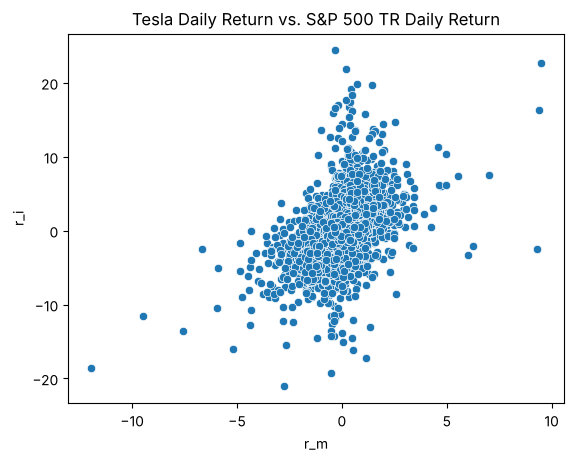

In [16]:
sns.scatterplot(data=returns, x="r_m", y="r_i")
plt.title("Tesla Daily Return vs. S&P 500 TR Daily Return")
plt.show()

## Market Model Regression

* Define the estimation period to be one year before the event date:

<mark>Q: How to define the estimation period before the event?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Use `.loc` to select the rows of `returns` from 365 days before `event_date` to 1 day before it, using `pd.DateOffset(days=365)` and `pd.DateOffset(days=1)`, and store their `.index` in `estimation_period`. Uncomment and run the following code.

In [17]:
estimation_period = returns.loc[event_date - pd.DateOffset(days=365)
                                     :event_date - pd.DateOffset(days=1)].index

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Select the rows of `returns` in `estimation_period` with `.loc`, drop missing values with `.dropna()`, and store the result in `returns_for_estimation`.

In [18]:
returns_for_estimation = returns.loc[estimation_period].dropna()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display `returns_for_estimation`.

In [19]:
returns_for_estimation

,r_i,r_m
Date,,
2017-08-07,-0.487523,0.167464
2017-08-08,2.829631,-0.229507
2017-08-09,-0.462737,-0.024658
2017-08-10,-2.236403,-1.411513
2017-08-11,0.694994,0.134186
...,...,...
2018-07-31,2.746659,0.491596
2018-08-01,0.905616,-0.103965
2018-08-02,16.188013,0.503052


<mark>Q: How to estimate the market model by regression?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Estimate the market model over the estimation period: set `y` to `returns_for_estimation['r_i']` and `X` to `returns_for_estimation['r_m']`, add a constant to `X` with `sm.add_constant()`, create the model `market_model` with `sm.OLS(y, X)`, fit it into `market_model_results`, and print its summary. Uncomment and run the following code.

In [20]:
y = returns_for_estimation['r_i']
X = returns_for_estimation['r_m']
X = sm.add_constant(X) # Add a constant to the independent variable for the intercept

market_model = sm.OLS(y, X)
market_model_results = market_model.fit()

print(market_model_results.summary())

                            OLS Regression Results                            
Dep. Variable:                    r_i   R-squared:                       0.189
Model:                            OLS   Adj. R-squared:                  0.186
Method:                 Least Squares   F-statistic:                     58.30
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           4.76e-13
Time:                        02:28:08   Log-Likelihood:                -587.91
No. Observations:                 252   AIC:                             1180.
Df Residuals:                     250   BIC:                             1187.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0805      0.158     -0.508      0.6

## Event Date Return vs. Predicted Return

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Use `.loc` to get the market return on `event_date` from the `'r_m'` column of `returns`, and store it in `r_m_event_date`.

In [21]:
r_m_event_date = returns.loc[event_date, 'r_m']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Get the intercept and slope from `market_model_results.params`: store `'const'` in `a` and `'r_m'` in `b`.

In [22]:
a = market_model_results.params['const']
b = market_model_results.params['r_m']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Make a scatter plot of just one point corresponding to the event date, and also plot the regression line which gives the predicted return. Uncomment and run the code below.

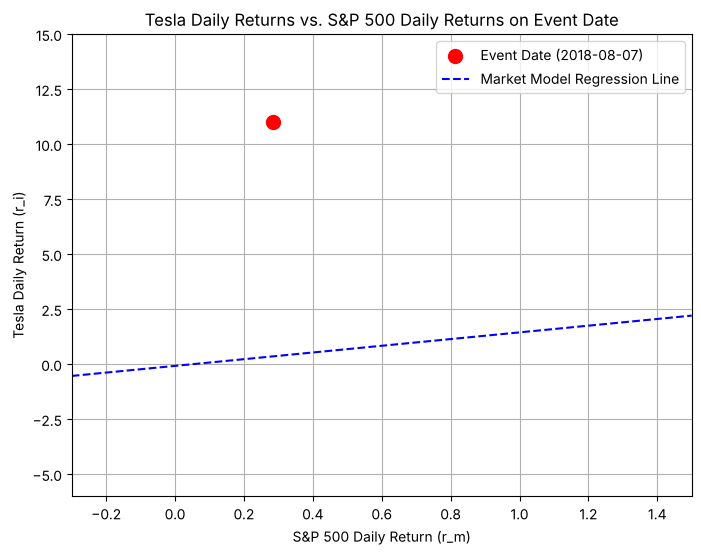

In [23]:
# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(r_m_event_date, r_i_event_date, color='red', marker='o', s=100,
            label=f'Event Date ({event_date.strftime("%Y-%m-%d")})')

# Set x and y limits as requested
plt.xlim(-0.3, 1.5)
plt.ylim(-6, 15)


# Add the regression line (equivalent to R's abline)
x_line = np.linspace(plt.xlim()[0], plt.xlim()[1], 100) # Generate x-values across the plot's x-range
y_line = a + b * x_line # Calculate corresponding y-values using the regression equation
plt.plot(x_line, y_line, color='blue', linestyle='--', label='Market Model Regression Line')

plt.title('Tesla Daily Returns vs. S&P 500 Daily Returns on Event Date')
plt.xlabel('S&P 500 Daily Return (r_m)')
plt.ylabel('Tesla Daily Return (r_i)')
plt.grid(True)
plt.legend()
plt.show()

## Abnormal Return

* First, calculate the predicted return:

<mark>Q: How to calculate the predicted return on the event date?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the predicted return on the event date as `a + b * r_m_event_date`, store it in `r_i_predicted`, and display it.

In [24]:
r_i_predicted = a + b * r_m_event_date
r_i_predicted

np.float64(0.3513674636720712)

* Next, calculate the abnomral return:

<mark>Q: How to calculate the abnormal return?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the abnormal return as `r_i_event_date` minus `r_i_predicted`, store it in `r_i_abnormal`, and display it.

In [25]:
r_i_abnormal = r_i_event_date - r_i_predicted
r_i_abnormal

np.float64(10.63725612404348)

### How signiﬁcant is the abnormal return?

<mark>Q: How to tell whether the abnormal return is statistically significant?</mark>

* We need to calculate the t statistic $$ \frac{AR}{\sigma_{residuals}}$$
  - AR is the abnormal return
  - $\sigma_{residuals}$ is the standard deviation of the residuals

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the standard deviation of the market model's residuals, `market_model_results.resid`, with `.std()`, store it in `sigma_residuals`, and display it.

In [26]:
sigma_residuals = market_model_results.resid.std()
sigma_residuals

np.float64(2.4993538389642422)

* The t-stat:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the t-statistic as `r_i_abnormal` divided by `sigma_residuals`, store it in `t_stat`, and display it.

In [27]:
t_stat = r_i_abnormal / sigma_residuals
t_stat

np.float64(4.256002474804315)